In [ ]:
# link of dataset: https://research.unsw.edu.au/projects/unsw-nb15-dataset
#I may work on this dataset on the final project

In [47]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("whitegrid")
df_train = pd.read_csv('./dataset/UNSW_NB15_training-set.csv')
df_test = pd.read_csv('./dataset/UNSW_NB15_testing-set.csv')
# basic information: 
print(df_train.shape)
print(df_train.info())
#check missing values:
print(df_train.isnull().sum().sum())# no missing values

(175341, 45)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  in

In [6]:
df_train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


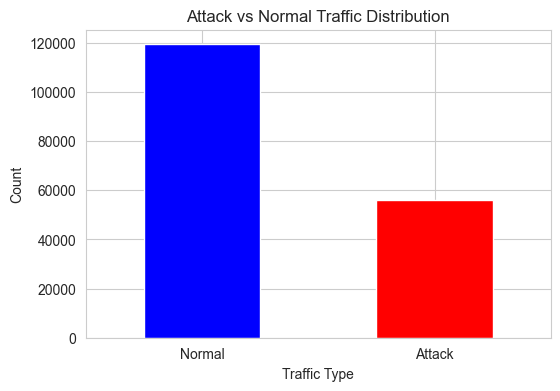

In [34]:
# **1. Check Attack vs Normal Class Distribution**
label_counts = df_train['label'].value_counts()

# Plot Attack vs Normal distribution
plt.figure(figsize=(6,4))
label_counts.plot(kind='bar', color=['blue', 'red'])
plt.xticks(ticks=[0,1], labels=['Normal', 'Attack'], rotation=0)
plt.xlabel("Traffic Type")
plt.ylabel("Count")
plt.title("Attack vs Normal Traffic Distribution")
# Save the visualization
plt.show()

In [13]:
# Select Only Numerical Features
categorical_features = df_train.select_dtypes(exclude= 'number').columns
categorical_features

Index(['proto', 'service', 'state', 'attack_cat'], dtype='object')

In [16]:
print(len(df_train['proto'].unique()))
df_train['proto'].unique()

133


array(['tcp', 'udp', 'arp', 'ospf', 'icmp', 'igmp', 'rtp', 'ddp',
       'ipv6-frag', 'cftp', 'wsn', 'pvp', 'wb-expak', 'mtp', 'pri-enc',
       'sat-mon', 'cphb', 'sun-nd', 'iso-ip', 'xtp', 'il', 'unas',
       'mfe-nsp', '3pc', 'ipv6-route', 'idrp', 'bna', 'swipe',
       'kryptolan', 'cpnx', 'rsvp', 'wb-mon', 'vmtp', 'ib', 'dgp',
       'eigrp', 'ax.25', 'gmtp', 'pnni', 'sep', 'pgm', 'idpr-cmtp',
       'zero', 'rvd', 'mobile', 'narp', 'fc', 'pipe', 'ipcomp', 'ipv6-no',
       'sat-expak', 'ipv6-opts', 'snp', 'ipcv', 'br-sat-mon', 'ttp',
       'tcf', 'nsfnet-igp', 'sprite-rpc', 'aes-sp3-d', 'sccopmce', 'sctp',
       'qnx', 'scps', 'etherip', 'aris', 'pim', 'compaq-peer', 'vrrp',
       'iatp', 'stp', 'l2tp', 'srp', 'sm', 'isis', 'smp', 'fire', 'ptp',
       'crtp', 'sps', 'merit-inp', 'idpr', 'skip', 'any', 'larp', 'ipip',
       'micp', 'encap', 'ifmp', 'tp++', 'a/n', 'ipv6', 'i-nlsp',
       'ipx-n-ip', 'sdrp', 'tlsp', 'gre', 'mhrp', 'ddx', 'ippc', 'visa',
       'secure-vmtp', 

In [17]:
print(len(df_train['state'].unique()))
df_train['state'].unique()

9


array(['FIN', 'INT', 'CON', 'ECO', 'REQ', 'RST', 'PAR', 'URN', 'no'],
      dtype=object)

In [18]:
print(len(df_train['attack_cat'].unique()))# multiclass labels
df_train['attack_cat'].unique()

10


array(['Normal', 'Backdoor', 'Analysis', 'Fuzzers', 'Shellcode',
       'Reconnaissance', 'Exploits', 'DoS', 'Worms', 'Generic'],
      dtype=object)

In [20]:
numerical_features = df_train.select_dtypes(include=['int64', 'float64']).columns
print(len(numerical_features))
numerical_features 

41


Index(['id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl',
       'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit',
       'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat',
       'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src',
       'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm',
       'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd',
       'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'label'],
      dtype='object')

In [ ]:
len(df_train['id'].unique())# should be dropped because unique values for each record

175341

In [26]:
len(df_train['dur'].unique())
df_train['dur'].unique()

array([0.121478, 0.649902, 1.623129, ..., 3.71911 , 0.996503, 1.557125],
      shape=(74039,))

In [29]:
df_train['sbytes'].unique()

array([   258,    734,    364, ..., 272070,  69997,  12601], shape=(7214,))

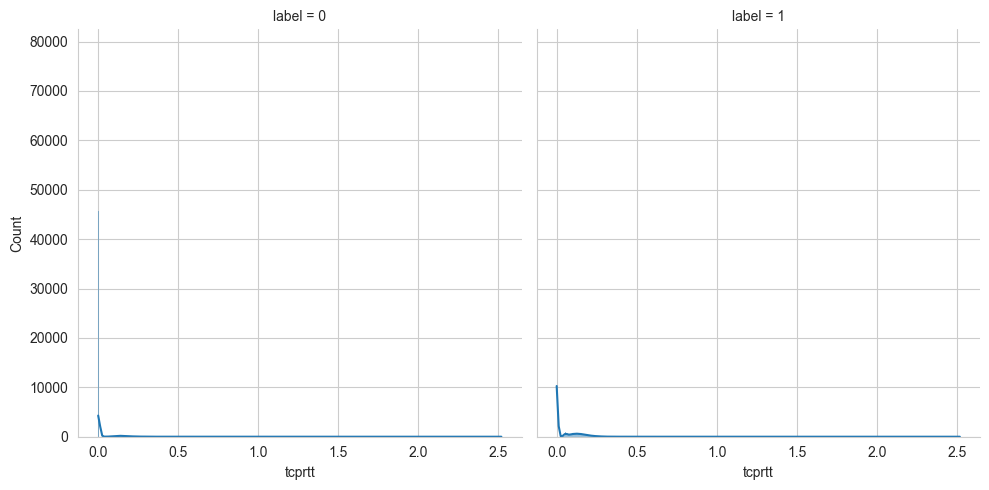

In [35]:
sns.displot(data = df_train, x = 'tcprtt', col = 'label', kde = True)
plt.show()

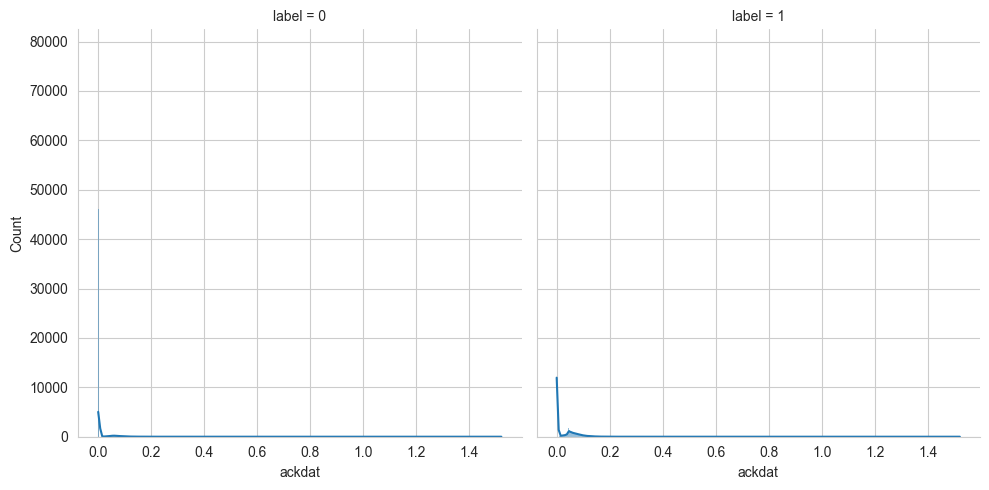

In [37]:
sns.displot(data = df_train, x = 'ackdat', col = 'label', kde = True)
plt.show()

In [ ]:
sns.displot(data = df_train, x = 'tcprtt', col = 'label', kde = True)
plt.show()

In [ ]:
#  27  smean              175341 non-null  int64  
#  28  dmean              175341 non-null  int64  
#  29  trans_depth        175341 non-null  int64  
#  30  response_body_len  175341 non-null  int64  
#  31  ct_srv_src         175341 non-null  int64  
#  32  ct_state_ttl       175341 non-null  int64  
#  33  ct_dst_ltm         175341 non-null  int64  
#  34  ct_src_dport_ltm   175341 non-null  int64  
#  35  ct_dst_sport_ltm   175341 non-null  int64  
#  36  ct_dst_src_ltm     175341 non-null  int64  
#  37  is_ftp_login       175341 non-null  int64  
#  38  ct_ftp_cmd         175341 non-null  int64  
#  39  ct_flw_http_mthd   175341 non-null  int64  
#  40  ct_src_ltm         175341 non-null  int64  
#  41  ct_srv_dst         175341 non-null  int64  
#  42  is_sm_ips_ports    175341 non-null  int64  

In [69]:
features = [  'smean',  'dmean' ,               
 'trans_depth' ,       
'response_body_len'  , 
 'ct_srv_src'  ,       
 'ct_state_ttl' ,       
 'ct_dst_ltm'      ,  
 'ct_src_dport_ltm'   , 
  'ct_dst_sport_ltm'  ,  
 'ct_dst_src_ltm'  , 
  'is_ftp_login'    ,   
  'ct_ftp_cmd'      ,   
 'ct_flw_http_mthd' ,   
  'ct_src_ltm'    ,    
 'ct_srv_dst'     ,   
 'is_sm_ips_ports'  ]  
for feature in features: 
    print( feature, " " , len(df_train[feature].unique()))

smean   1357
dmean   1328
trans_depth   11
response_body_len   2386
ct_srv_src   52
ct_state_ttl   5
ct_dst_ltm   50
ct_src_dport_ltm   47
ct_dst_sport_ltm   32
ct_dst_src_ltm   54
is_ftp_login   4
ct_ftp_cmd   4
ct_flw_http_mthd   11
ct_src_ltm   50
ct_srv_dst   52
is_sm_ips_ports   2


In [72]:
df_train['ct_ftp_cmd'].value_counts()

ct_ftp_cmd
0    172774
1      2545
4        16
2         6
Name: count, dtype: int64

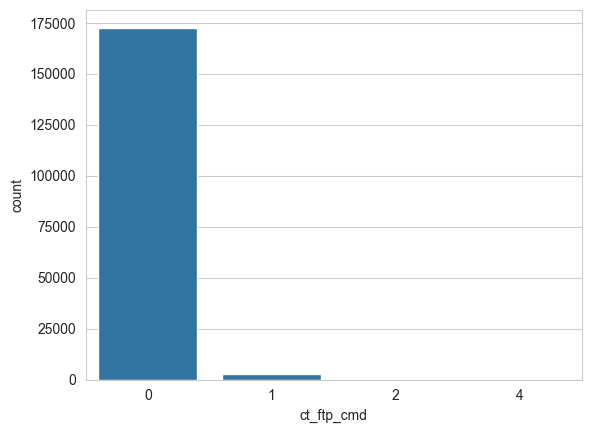

In [71]:
#basic ways instead counts:
sns.countplot(data = df_train, x = 'ct_ftp_cmd')
plt.show()

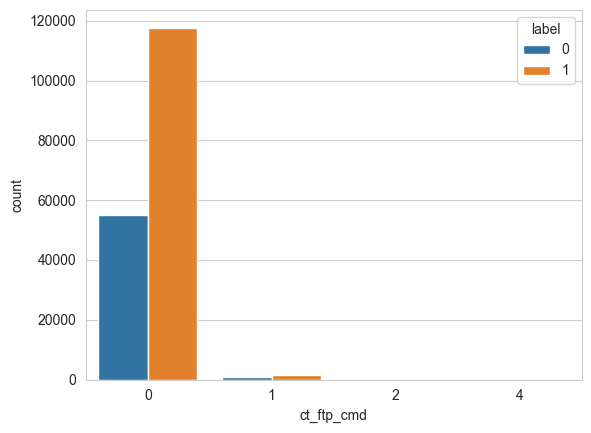

In [73]:
#use hue to divide based on smoker:
sns.countplot(data = df_train, x = 'ct_ftp_cmd',  hue= 'label')
plt.show()

In [74]:
df_train['is_ftp_login'].value_counts()

is_ftp_login
0    172774
1      2545
4        16
2         6
Name: count, dtype: int64

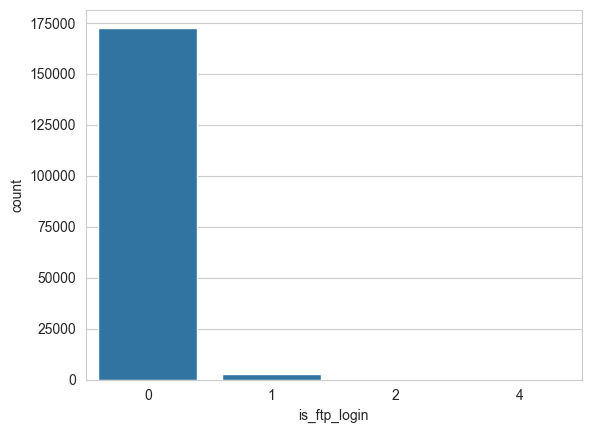

In [70]:
#basic ways instead counts:
sns.countplot(data = df_train, x = 'is_ftp_login')
plt.show()

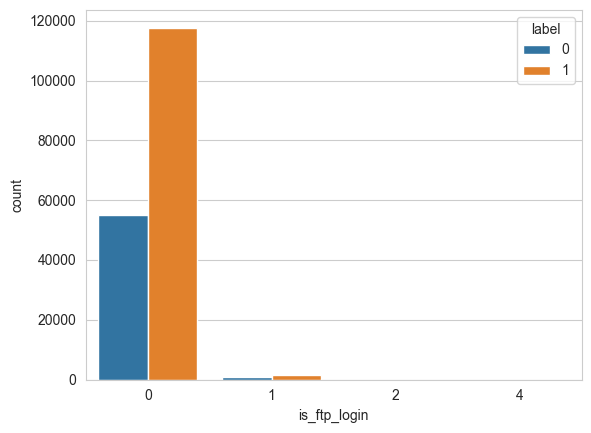

In [75]:
sns.countplot(data = df_train, x = 'is_ftp_login', hue = 'label')
plt.show()

In [49]:
df_train.shape, df_test.shape

((175341, 45), (82332, 45))

In [50]:
df_train.columns

Index(['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='object')

In [51]:
df_train.drop(columns=["id", "attack_cat", 'dur','proto', 'service', 'state' ], inplace = True)
df_test.drop(columns=["id", "attack_cat", 'dur','proto', 'service', 'state'], inplace = True)

In [52]:
df_train.shape, df_test.shape

((175341, 39), (82332, 39))

In [53]:
df_train.columns

Index(['spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload',
       'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin',
       'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean',
       'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src',
       'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm',
       'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd',
       'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'label'],
      dtype='object')

In [55]:
X_train , y_train = df_train.iloc[:, :-1], df_train.iloc[:, -1]
X_test , y_test  = df_test.iloc[:, :-1], df_test.iloc[:, -1]

In [57]:
X_train.shape , y_train.shape

((175341, 38), (175341,))

In [65]:
from sklearn.preprocessing import StandardScaler
sc= StandardScaler()
sc.fit(X_train)# learn mean and std for each column
X_train_normalized = sc.transform(X_train)
X_test_normalized  = sc.transform(X_test)

In [61]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB 
from sklearn.svm import LinearSVC
from sklearn.linear_model import Perceptron
knn_classifier = KNeighborsClassifier(n_neighbors=5, weights='uniform', algorithm='auto')
gnb = GaussianNB()
linear_SVM = LinearSVC(penalty='l2', loss='squared_hinge')
perceptron_model = Perceptron(penalty=None, alpha=0.0001) 

In [67]:
# KNN
knn_classifier.fit(X_train_normalized, y_train)
y_pred_knn = knn_classifier.predict(X_test_normalized)

# Gaussian Naive Bayes
gnb.fit(X_train_normalized, y_train)
y_pred_gnb = gnb.predict(X_test_normalized)

# Linear SVM
linear_SVM.fit(X_train_normalized, y_train)
y_pred_svm = linear_SVM.predict(X_test_normalized)

# Perceptron
perceptron_model.fit(X_train_normalized, y_train)
y_pred_perceptron = perceptron_model.predict(X_test_normalized)

In [68]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluate_model(y_true, y_pred, model_name):
    print(f"\n===== {model_name} =====")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# Evaluate all classifiers
evaluate_model(y_test, y_pred_knn, "KNN")
evaluate_model(y_test, y_pred_gnb, "Gaussian Naive Bayes")
evaluate_model(y_test, y_pred_svm, "Linear SVM")
evaluate_model(y_test, y_pred_perceptron, "Perceptron")


===== KNN =====
Accuracy: 0.8268

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.69      0.78     37000
           1       0.79      0.94      0.86     45332

    accuracy                           0.83     82332
   macro avg       0.84      0.81      0.82     82332
weighted avg       0.84      0.83      0.82     82332

Confusion Matrix:
[[25682 11318]
 [ 2944 42388]]

===== Gaussian Naive Bayes =====
Accuracy: 0.7324

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.51      0.63     37000
           1       0.70      0.91      0.79     45332

    accuracy                           0.73     82332
   macro avg       0.76      0.71      0.71     82332
weighted avg       0.75      0.73      0.72     82332

Confusion Matrix:
[[19006 17994]
 [ 4040 41292]]

===== Linear SVM =====
Accuracy: 0.7840

Classification Report:
              precision    recall  f1-score   supp